# 5. Precision docking and narrow passages

In this notebook, we plan paths for the 2WS and the 4WS vehicles in a docking
problem and through a narrow passage, compare the docking paths with those of
the sampling planners, and solve both problems again at the transition costs
of the parameter study.

Reaching a pose is not the same problem as reaching a place. A forklift picking
up a pallet has to arrive at a given position *and* a given heading, in a space
barely larger than itself. This is where the second steering axle makes a
difference, and where the manoeuvring modes of notebook 4 engage.

Both scenes are in `data/maps/`. The first is a docking problem on a 100 by
150 grid at `zoom=20`, one grid unit to five centimetres: a bay cut into the
left wall, 4.4 m long and 1.5 m deep, to be reached sideways, as in parallel
parking. The second is a cluttered hall with a narrow passage along the top,
which only one of the two vehicles can use.

Every solve below uses the settings of the comparisons with the sampling
planners:

* transition costs $k_1 = 2$, $k_2 = 3$ and the reference speed coefficients;
* a steering saturation of 1.05 rad on both axles for docking, about 60
  degrees, without which no crab fits in the bay, and of 0.5 rad on the narrow
  passage;
* the start mode left free (`free_start_mode=True`): a vehicle at rest leaves
  in any mode at no transition cost;
* the PastSeed criterion of the backtracking delayed to 128 steps (agd's
  default is 8);
* the clearance term of the cost capped at the vehicle length, the default.

Each path is then cleaned in two steps before it is measured or drawn.
`shfm.postprocess.dechatter` removes the back-and-forth steps the extraction can
leave near the start, and `shfm.splice.close_start` replaces the first stretch
by a connection that starts exactly on the requested pose.

As in notebook 7, the sampling planners are not re-run: their campaigns are
read from `data/campaigns/`. Four of the five are anytime, so a re-run would be
a new sample of the same distribution rather than the comparison shipped here.

**Summary**

1. [The docking scene](#1)
2. [Two axles against one](#2)
3. [Reading the crab](#3)
4. [Against the sampling planners](#4)
5. [A corridor only one of them can use](#5)
6. [The price of the manoeuvring mode](#6)

In [1]:
import sys, os, logging
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import cupy as cp
import matplotlib.pyplot as plt
from IPython.display import Image, display

from shfm import DEFAULT_VEHICLE, from_benchmark_run, Planner, REFERENCE_COEFFICIENTS
from shfm import benchmark as B, metrics as M, plates as PL
from shfm.kinematics import control_set, control_set_2ws
from shfm.postprocess import dechatter, reversals
from shfm.splice import close_start
from shfm.figures import FIGURE_DIR, save

os.makedirs(FIGURE_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})   # font size left at the matplotlib default, as the plates were drawn
logging.getLogger("fontTools").setLevel(logging.ERROR)   # font notices of the PDF plates

K1, K2 = 2.0, 3.0                               # transition costs of the comparisons
PASTSEED = dict(geodesic_PastSeed_delay=128)    # agd's default is 8 steps
BASELINES = "rrt,sst,rrtstar,informedrrtstar,spars"


def problem(name, zoom, run_index=0):
    "Environment, start and goal (x, y, theta) of one run of a campaign."
    run = B.load_campaign(name)["runs"][run_index]
    env = from_benchmark_run(run, zoom=zoom, n_theta=100, vehicle=DEFAULT_VEHICLE)
    start, goal = B.endpoints_of(run)
    return env, list(start), list(goal)


def plan_path(env, start, goal, vehicle, delta, k1=K1, k2=K2):
    """One solve, then the two corrections.

    Returns the path in the order it is driven, (n, 4): x, y, theta, mode index
    in solver order; and what close_start did (``joined`` is None when no
    connection qualified and the start was left as extracted).
    """
    builder = control_set if vehicle == "4WS" else control_set_2ws
    controls = lambda th, wb, xp: builder(th, wb, xp=xp, delta_f_max=delta,
                                          delta_r_max=delta, **REFERENCE_COEFFICIENTS)
    r = Planner(env, k1=k1, k2=k2, controls=controls).solve(
        start + [0], [goal + [0]], free_start_mode=True, **PASTSEED)
    path = r.path(0)
    del r
    cp.get_default_memory_pool().free_all_blocks()
    path = dechatter(path)[0]
    return close_start(path, start, env, env.vehicle.wheelbase * env.zoom,
                       delta, delta if vehicle == "4WS" else 0.0)


def manoeuvre_share(path):
    "Share of the points of a path in a manoeuvring mode."
    modes = np.rint(path[:, 3]).astype(int)
    return float(np.mean((modes == 1) | (modes == 2)))


def measure(path, env, goal):
    """Bench-MR metrics of a driven path, under the names of the campaign files.

    Bench-MR forms its curvature triples from one end of the path, so the order
    matters by a few percent; the curvature is measured on the reversed path,
    goal to start, the order the solver produces. The AHE looks at the final
    poses, over the vehicle length, and is measured on the driven order.
    """
    p = np.asarray(path, dtype=float)[:, :3]
    with M.quiet():
        max_k, norm_k = M.curvature(p[::-1])
        clear = M.clearing_distances(p, env.walls)
        return {"path_length": M.path_length(p),
                "normalized_curvature": norm_k,
                "max_curvature": max_k,
                "min_clearing_distance": float(clear.min()),
                "approach_heading_error": M.approach_heading_error(
                    p, goal[2], env.vehicle.length * env.zoom),
                "swept_area": M.swept_area(p, env.vehicle, env.zoom),
                "cusps": len(reversals(path)),
                "manoeuvre": manoeuvre_share(path)}

<a id='1'></a>
## 1. The docking scene

The vehicle starts in the open, at the bottom, and must end up inside the bay
on the left, pointing the same way. The scene and its two poses are read from
the campaign file rather than restated here; the scale is set in the next cell.

In [2]:
DOCK_ZOOM, DOCK_DELTA = 20.0, 1.05
docking = B.load_campaign("docking")
docking_file = B.campaign_file("docking")
env, start, goal = problem("docking", DOCK_ZOOM)

print(env)
print("vehicle length in grid units: %.0f" % (env.vehicle.length * env.zoom))
print("free fraction of the lifted space: %.3f" % (~env.walls3).mean())
print("start %s  goal %s" % (tuple(round(v, 2) for v in start),
                             tuple(round(v, 2) for v in goal)))
print("%d runs, planners %s" % (len(docking["runs"]),
      ", ".join(sorted({k for r in docking["runs"] for k, v in r["plans"].items() if v}))))

Environment(name='grid', shape=(100, 150), n_theta=100, zoom=20.0, 1 unit = 0.05 m)
vehicle length in grid units: 73
free fraction of the lifted space: 0.105
start (60.0, 20.0, 1.57)  goal (25.0, 65.0, 1.57)
20 runs, planners InformedRRTstar, RRT, RRTstar, SPARS, SST


<a id='2'></a>
## 2. Two axles against one

Both vehicles use the same planner, cost and state system; the only difference
is whether the rear axle may steer.

In [3]:
driven, splice = {}, {}
for vehicle in ("2WS", "4WS"):
    driven[vehicle], splice[vehicle] = plan_path(env, start, goal, vehicle, DOCK_DELTA)

for vehicle, p in driven.items():
    m = measure(p, env, goal)
    print("SHFM %s  length %6.1f   swept area %5.1f m2   %d cusps   manoeuvring on %4.1f%% of the points"
          % (vehicle, m["path_length"], m["swept_area"], m["cusps"], 100 * m["manoeuvre"]))

# On a fixed scene the one path stands for every run of the campaign.
n_runs = len(docking["runs"])
ours = [[driven["2WS"][:, :3]] * n_runs, [driven["4WS"][:, :3]] * n_runs]

SHFM 2WS  length  114.5   swept area  12.7 m2   6 cusps   manoeuvring on  0.0% of the points
SHFM 4WS  length   86.2   swept area  11.8 m2   2 cusps   manoeuvring on 26.2% of the points


The 2WS vehicle reaches the bay the way a car parallel-parks: it drives past
it and reverses in, with six cusps. The 4WS vehicle reverses only over the
last stretch, in which it crabs into the bay, with two cusps and about a
quarter of its points in a manoeuvring mode; its path is a quarter shorter,
86.2 cells against 114.5.

The plate below is drawn by Bench-MR itself, with every sampling planner hidden:
it shows the 4WS vehicle. The plate of the 2WS vehicle is written to
`figures/05_creneau_2ws.pdf`.

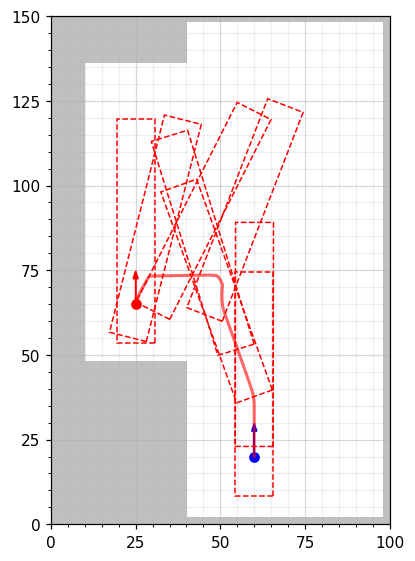

In [4]:
for label, hidden in (("2ws", "shfm4ws"), ("4WS", "shfm2ws")):
    PL.trajectories(docking_file, ours, every_nth=60, run_id="0", silence=True,
                    ignore_planners=BASELINES + "," + hidden,
                    save_file=os.path.join(FIGURE_DIR, "05_creneau_%s.pdf" % label))

<a id='3'></a>
## 3. Reading the crab

The plates draw the track of the rear-axle centre, not the direction in which
the vehicle points, and in a manoeuvring mode the two need not agree: the 4WS
path can therefore be misread.

We draw below the 4WS path on the docking scene, coloured by mode, with its
cusps, the start and goal footprints, and one footprint halfway through the
backward manoeuvre with two arrows: the dashed one along the heading, the solid
one along the direction in which the rear-axle centre moves.

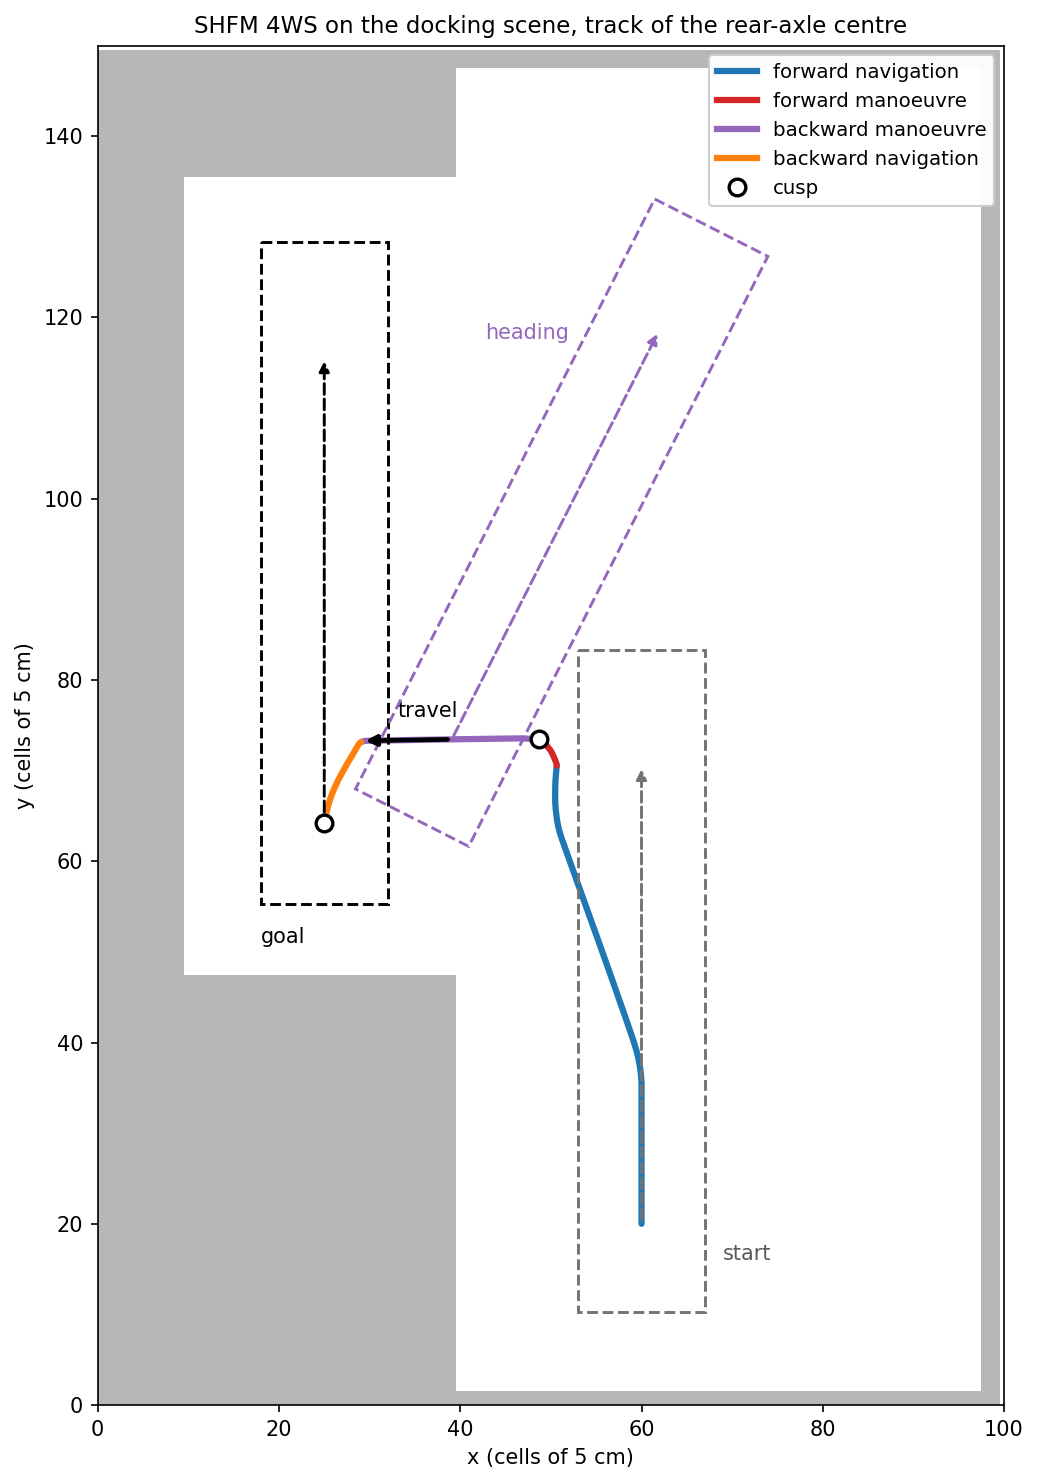

forward navigation    52.3 cells
forward manoeuvre      3.3 cells
backward manoeuvre    20.1 cells
backward navigation    9.8 cells
forward navigation     0.8 cells


In [5]:
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
from shfm.plotting import STATE_COLORS
from shfm.states import SOLVER_ORDER

MODE_NAME = {"nav_fwd": "forward navigation", "nav_bwd": "backward navigation",
             "man_fwd": "forward manoeuvre", "man_bwd": "backward manoeuvre"}


def draw_vehicle(ax, pose, colour, travel=None):
    "Dashed footprint, an arrow along the heading and, if given, one along the travel."
    v, z = env.vehicle, env.zoom
    ax.add_patch(Polygon(v.footprint_polygon(pose[0], pose[1], pose[2], z), closed=True,
                         fill=False, ls="--", lw=1.4, edgecolor=colour, zorder=4))
    nose = np.asarray(pose[:2]) + 0.8 * (v.length - v.rear_axle_offset) * z * np.array(
        [np.cos(pose[2]), np.sin(pose[2])])
    ax.annotate("", xy=nose, xytext=pose[:2], zorder=5,
                arrowprops=dict(arrowstyle="-|>", color=colour, lw=1.4, ls="--"))
    if travel is not None:
        ax.annotate("", xy=np.asarray(pose[:2]) + 10 * np.asarray(travel), xytext=pose[:2],
                    zorder=6, arrowprops=dict(arrowstyle="-|>", color="black", lw=2.2))
    return nose


path = driven["4WS"]
modes = np.rint(path[:, 3]).astype(int)
segments = np.split(np.arange(len(path)), np.flatnonzero(np.diff(modes)) + 1)

fig, ax = plt.subplots(figsize=(8.5, 10))
ax.set_aspect("equal")
ax.pcolormesh(env.X[0], env.X[1], env.walls.astype(float), cmap="Greys", vmin=0, vmax=1.7,
              alpha=0.55, shading="auto")
for idx in segments:
    seg = path[max(idx[0] - 1, 0):idx[-1] + 1]
    ax.plot(seg[:, 0], seg[:, 1], color=STATE_COLORS[SOLVER_ORDER[modes[idx[0]]]], lw=3.0,
            solid_capstyle="round", zorder=3)
cusp_xy = path[reversals(path) + 1]
ax.plot(cusp_xy[:, 0], cusp_xy[:, 1], "o", ms=8, mfc="white", mec="black", mew=1.6, zorder=7)
draw_vehicle(ax, start, "0.45")
draw_vehicle(ax, goal, "black")
ax.text(start[0] + 9, start[1] - 4, "start", fontsize=10, color="0.35")
ax.text(goal[0] - 7, goal[1] - 14, "goal", fontsize=10)
crab = np.flatnonzero(modes == SOLVER_ORDER.index("man_bwd"))
k = crab[len(crab) // 2]
d = path[k + 1, :2] - path[k, :2]
nose = draw_vehicle(ax, path[k], STATE_COLORS["man_bwd"], travel=d / np.linalg.norm(d))
ax.text(path[k, 0] - 6, path[k, 1] + 2.5, "travel", fontsize=10)
ax.text(nose[0] - 10, nose[1] - 1, "heading", fontsize=10, ha="right",
        color=STATE_COLORS["man_bwd"])
ax.set_xlim(0, 100)
ax.set_ylim(0, 150)
ax.set_xlabel("x (cells of 5 cm)")
ax.set_ylabel("y (cells of 5 cm)")
ax.set_title("SHFM 4WS on the docking scene, track of the rear-axle centre", fontsize=11)
handles = [Line2D([], [], color=STATE_COLORS[n], lw=3, label=MODE_NAME[n])
           for n in ("nav_fwd", "man_fwd", "man_bwd", "nav_bwd")]
handles.append(Line2D([], [], ls="none", marker="o", ms=8, mfc="white", mec="black",
                      mew=1.6, label="cusp"))
ax.legend(handles=handles, loc="upper right", fontsize=9.5, framealpha=0.95)
fig.tight_layout()
display(Image(save(fig, "05_crab")[0]))
plt.close(fig)

# The path, mode by mode, in the order it is driven.
step = np.hypot(*np.diff(path[:, :2], axis=0).T)
for idx in segments:
    print("%-20s %5.1f cells" % (MODE_NAME[SOLVER_ORDER[modes[idx[0]]]],
                                 step[idx[0]:min(idx[-1] + 1, len(step))].sum()))

Along the path, the vehicle first drives up in forward navigation, its
rear-axle centre following its heading. Level with the bay it switches to the
forward manoeuvring mode, stops at the first cusp, and goes on in the backward
manoeuvring mode. There the two arrows part: the rear-axle centre moves
straight to the left, into the bay and at right angles to its back wall, while
the vehicle keeps pointing up and to the right. Both axles are steered to the
same side, so the chassis moves sideways with its heading almost unchanged: the
vehicle is crabbing, not driving in. It crabs this way for about twenty cells,
a metre, then switches to backward navigation and reverses onto the goal,
turning towards the goal heading. The second cusp, just before the goal, is a
last forward adjustment of less than a cell.

A 2WS vehicle cannot do this: its rear axle does not steer, so its rear-axle
centre always moves along its heading, and it reaches the bay by driving past
it and reversing in, as in section 2.

<a id='4'></a>
## 4. Against the sampling planners

The table covers the five sampling planners over the twenty runs of the
campaign, and this planner once per vehicle, since its path does not change
from one run to the next. For the sampling planners it gives the mean and the
sample standard deviation over every run, including the runs that did not
reach the pose; the second column says how many did. Notebook 8 leaves those
runs out. The AHE, the Approach Heading Error of the thesis, is the exception:
a run that stops short has no approach to measure, so it is averaged over the
runs that reached the pose, with the population standard deviation, as printed
in the thesis.

The normalised curvature stored in the campaign files carries an error of the
build of Bench-MR the campaigns were run with (`external/NOTICE.md`). We
measure it again here on the trajectories of the sampling planners, with the
corrected metric. The campaign files do not hold the AHE, which is measured
on the trajectories too; the other columns are the stored statistics.

In [6]:
COLS = [("path_length", "length"), ("normalized_curvature", "curv.norm"),
        ("max_curvature", "curv.max"), ("min_clearing_distance", "clear.min"),
        ("approach_heading_error", "AHE")]
DDOF = {"approach_heading_error": 0}   # population spread for the AHE, as in the thesis

values, attempts, reached = {}, {}, {}
for run in docking["runs"]:
    for planner, plan in run["plans"].items():
        if plan is None:
            continue
        attempts[planner] = attempts.get(planner, 0) + 1
        reached[planner] = reached.get(planner, 0) + B.reached_goal(plan)
        stats = dict(plan.get("stats") or {})
        if plan.get("trajectory"):
            with M.quiet():
                stats["normalized_curvature"] = M.normalized_curvature(
                    np.asarray(plan["trajectory"], dtype=float)[:, :3])
        for key, _ in COLS:
            if stats.get(key) is not None:
                values.setdefault(planner, {}).setdefault(key, []).append(float(stats[key]))
# Runs that reached the pose only, over the vehicle length.
for planner, stats in PL.campaign_ahe(docking_file, DOCK_ZOOM).items():
    values.setdefault(planner, {}).update(stats)

head = "%-16s%8s" % ("planner", "reached") + "".join("%20s" % c for _, c in COLS)
print(head); print("-" * len(head))
for planner in sorted(attempts):
    v = values.get(planner, {})
    print("%-16s%8s" % (planner, "%d/%d" % (reached[planner], attempts[planner]))
          + "".join("%20s" % ("--" if not v.get(k) else
                              "%.3f +/- %.3f" % (np.mean(v[k]), np.std(v[k], ddof=DDOF.get(k, 1))))
                    for k, _ in COLS))
print("-" * len(head))
for vehicle in ("2WS", "4WS"):
    m = measure(driven[vehicle], env, goal)
    print("%-16s%8s" % ("SHFM_" + vehicle, "1/1") + "".join("%20.3f" % m[k] for k, _ in COLS))

planner          reached              length           curv.norm            curv.max           clear.min                 AHE
----------------------------------------------------------------------------------------------------------------------------
InformedRRTstar    20/20    96.726 +/- 2.151     2.874 +/- 0.793     1.904 +/- 1.676     9.988 +/- 1.459     0.484 +/- 0.076
RRT                20/20  166.350 +/- 48.473     8.397 +/- 5.918     2.365 +/- 2.013    11.423 +/- 1.961     0.793 +/- 0.382
RRTstar            20/20    97.473 +/- 2.075     3.238 +/- 1.041     2.218 +/- 1.985    10.323 +/- 1.151     0.536 +/- 0.088
SPARS              20/20  135.274 +/- 26.605     6.018 +/- 2.672     2.357 +/- 1.763    12.462 +/- 1.727     0.725 +/- 0.266
SST                13/20  134.859 +/- 22.287     8.496 +/- 3.030     3.833 +/- 1.661    12.146 +/- 1.631     0.740 +/- 0.235
----------------------------------------------------------------------------------------------------------------------------


These are the values `generators/comparison_plates.py` writes to
`figures/tables/docking.md`.

The 4WS path is the shortest of the table, 86.2 cells against 96.7 for
Informed-RRT* and 97.5 for RRT*. It has the lowest maximum curvature, 0.65
against 1.90 and above, keeps the largest distance to the obstacles, 15.0
cells, and has the lowest AHE, 0.33 rad against 0.48 to 0.79 for the sampling
planners. Every path ends exactly on the goal pose, but the 4WS vehicle is
aligned with it earlier, the crab covering the remaining sideways offset. Its
normalised curvature, 3.26, is close to those of RRT* and Informed-RRT*, 3.24
and 2.87 on average, not below them. The 2WS path, with its six cusps, is
longer than those of RRT* and Informed-RRT* and has the largest normalised
curvature of the table, 10.19; its AHE, 0.47 rad, is still below those of the
sampling planners.

On an open layout a sampling planner reaches a place by many routes, and
refining any of them gives a short path; notebooks 7 and 8 show such scenes,
where this planner trades length for clearance (the table of notebook 8). In a
bay barely larger than the vehicle the set of feasible paths is thin and the
terminal constraint is a pose rather than a neighbourhood. A thin set is the
least favourable case for randomised planners.

The plate below shows two runs, ours beside RRT* and Informed-RRT*, the two
sampling planners with the shortest paths here: ours in red, RRT* in green,
Informed-RRT* in blue. The plates are displayed without their legend, which
the PDF files keep.

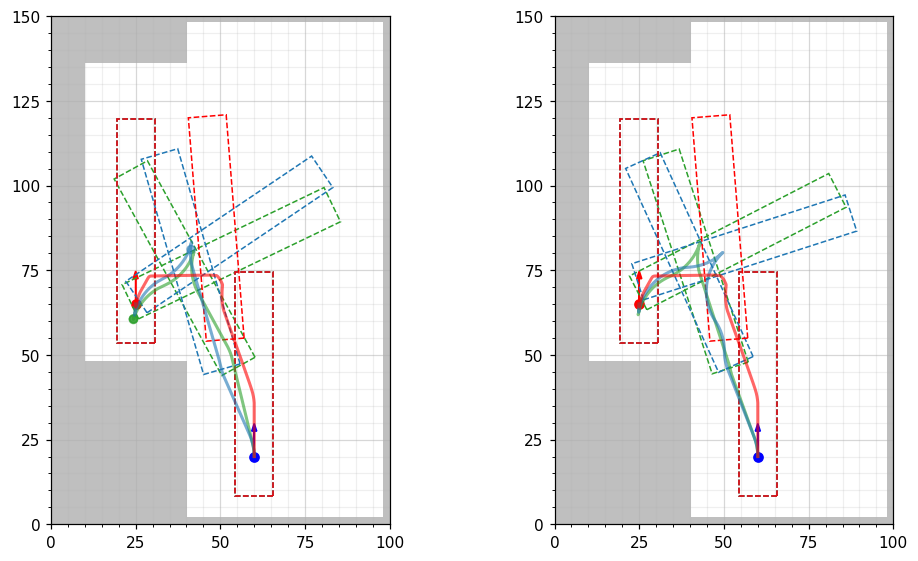

In [7]:
fig = PL.trajectories(docking_file, ours, every_nth=200, run_id="0,1", max_plots_per_line=2,
                      ignore_planners="rrt,sst,spars,shfm2ws", num_colors=5, silence=True,
                      save_file=os.path.join(FIGURE_DIR, "05_accostage_sota.pdf"))

The violins below show the same metrics, one per planner. They read the
statistics of the campaign file, so the normalised curvature, whose stored
value is wrong, is left out of them. The AHE of the sampling planners is
measured on the trajectories of the runs that reached the pose, which is why
the plates take the zoom of the scene. The summary plate also has a panel for
the AOL, the total change of the direction of travel over the path length
(`shfm.metrics.aol`).

Saved ../figures/05_creneau_path_length.pdf.
Saved ../figures/05_creneau_path_length_nolegend.pdf.


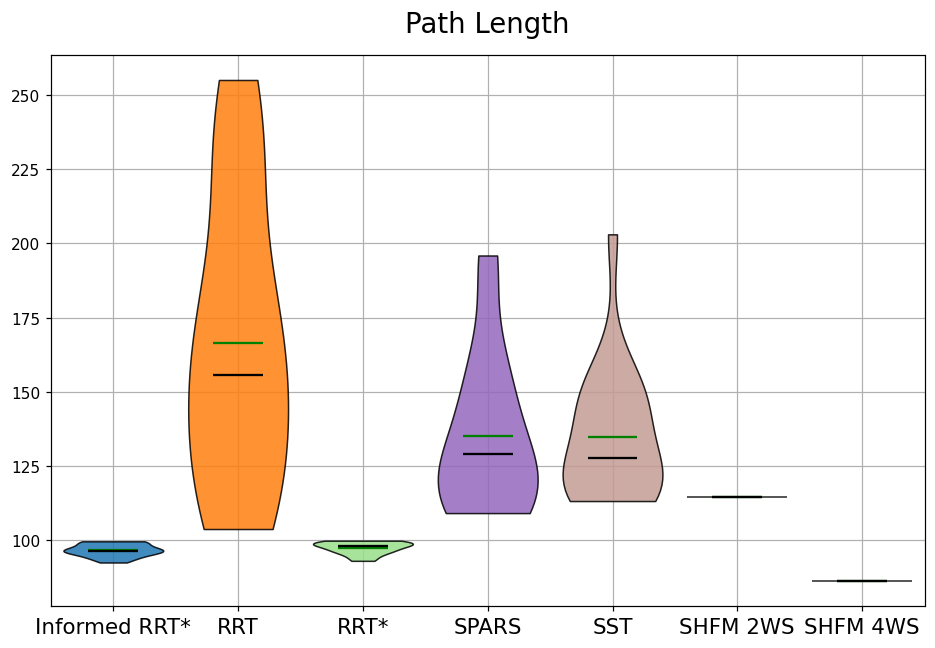

Saved ../figures/05_creneau_max_curvature.pdf.
Saved ../figures/05_creneau_max_curvature_nolegend.pdf.


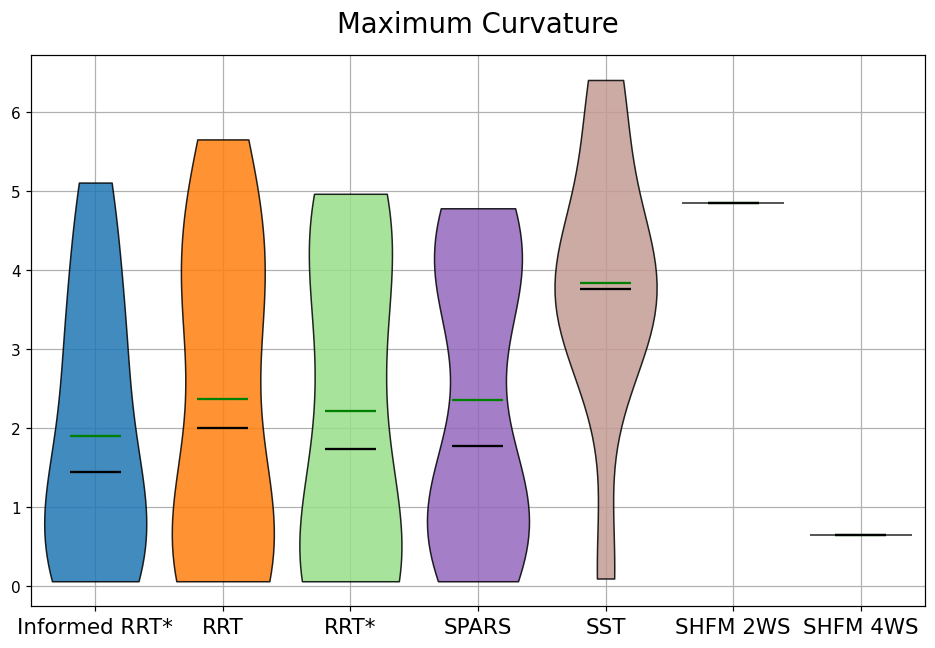

Saved ../figures/05_creneau_min_clearing_distance.pdf.
Saved ../figures/05_creneau_min_clearing_distance_nolegend.pdf.


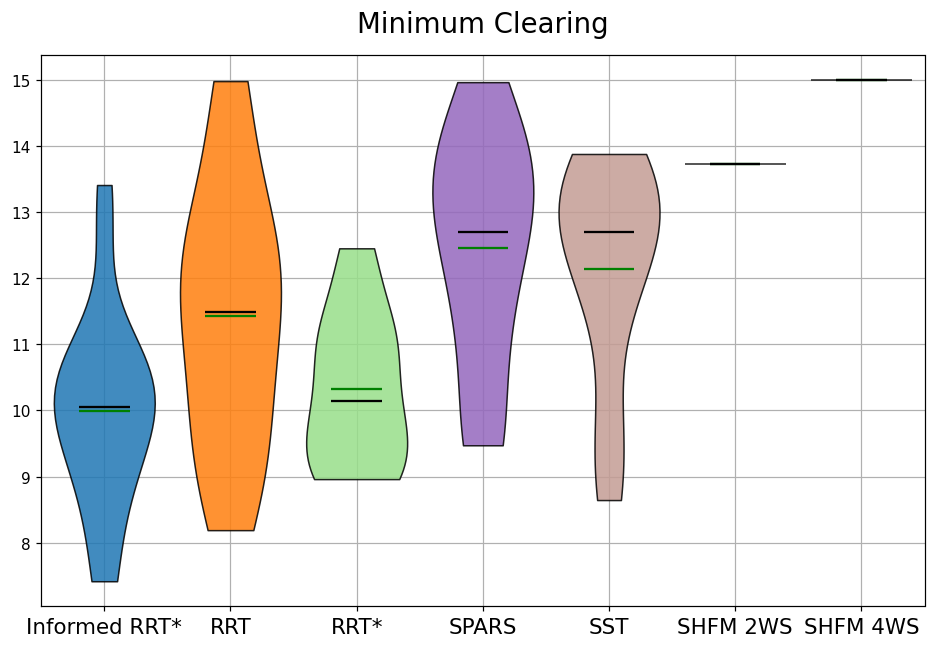

Saved ../figures/05_creneau_approach_heading_error.pdf.
Saved ../figures/05_creneau_approach_heading_error_nolegend.pdf.


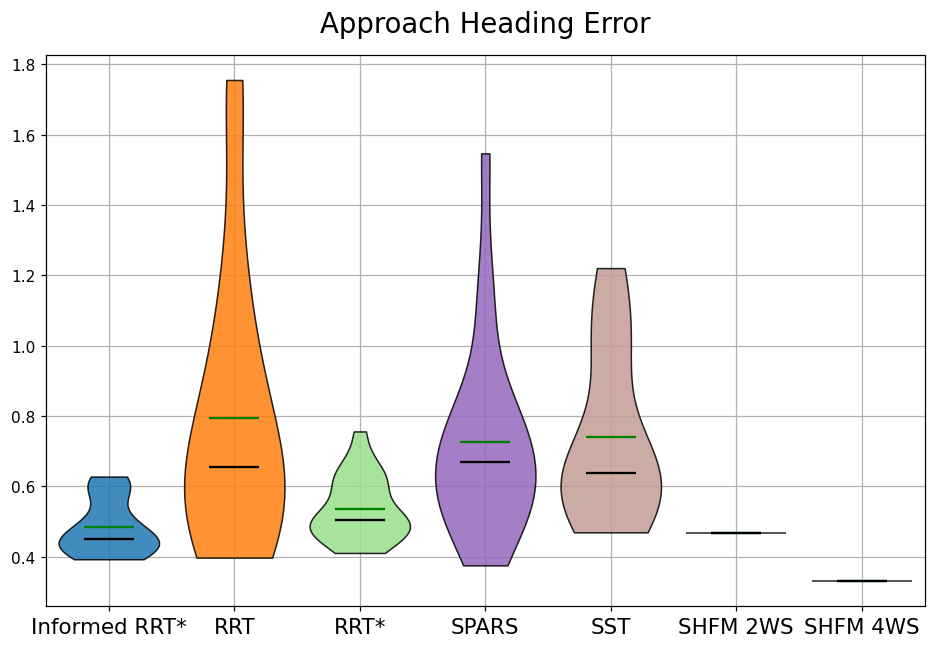

Saved ../figures/05_creneau_metrics.pdf.
Saved ../figures/05_creneau_metrics_nolegend.pdf.


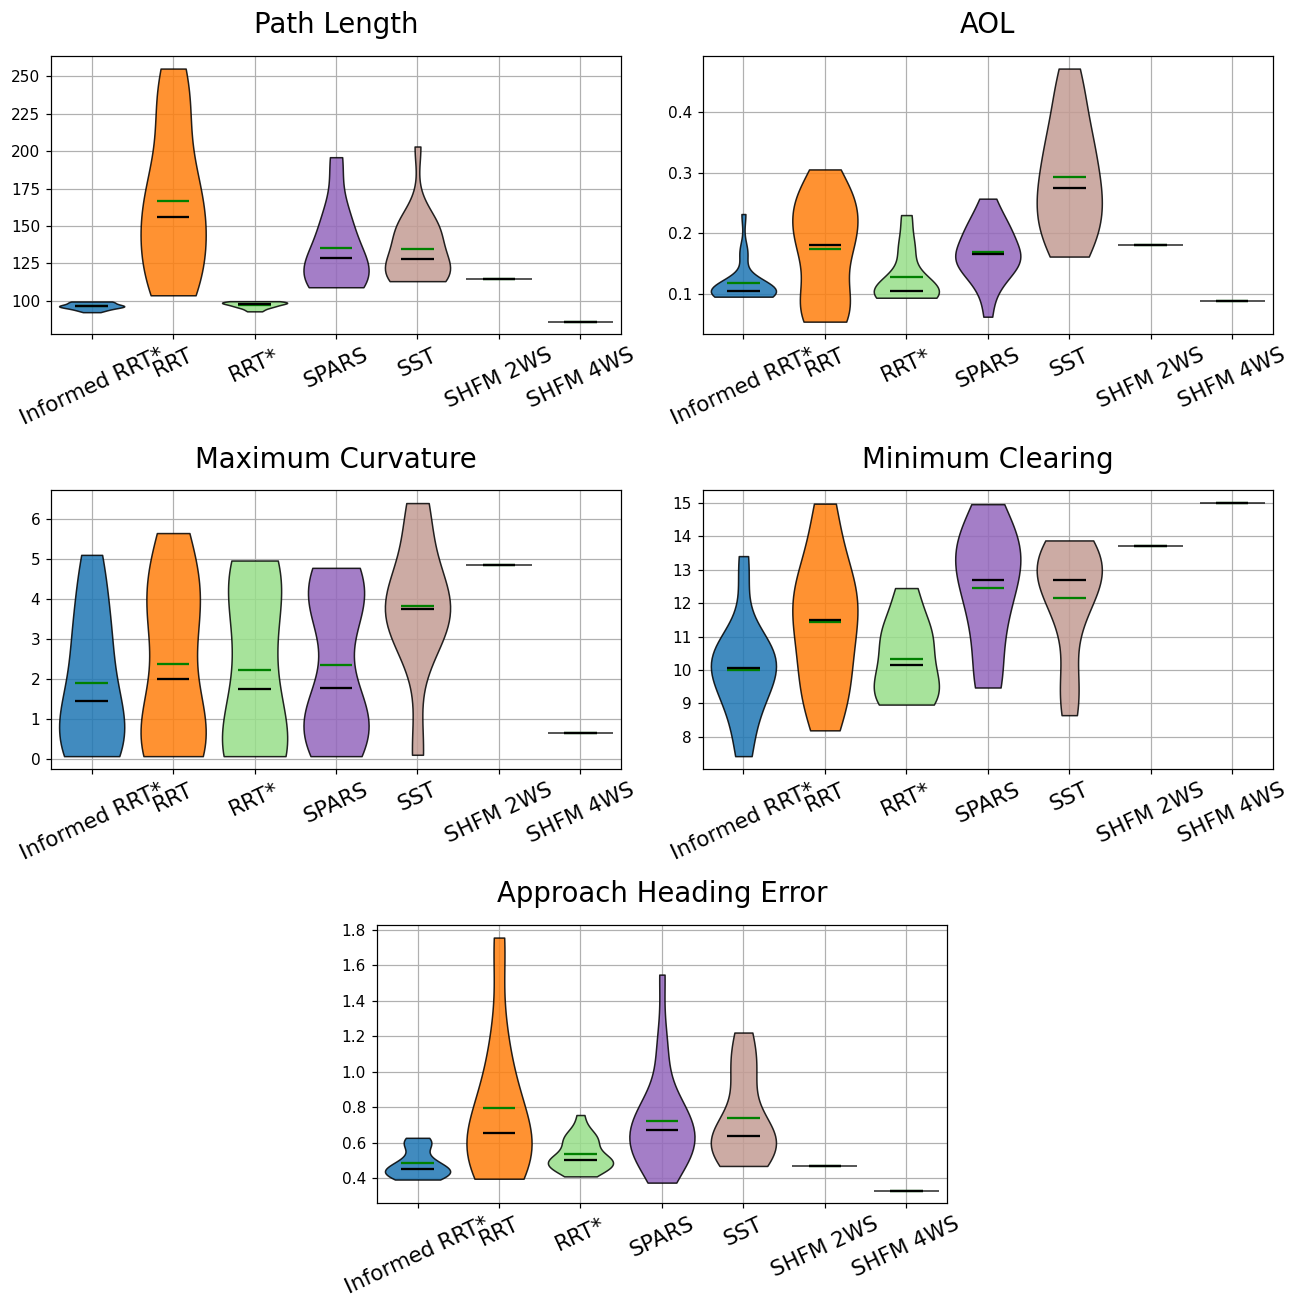

In [8]:
our_stats = PL.custom_stats({"SHFM_2WS": ours[0], "SHFM_4WS": ours[1]}, env, goal,
                            raw={"SHFM_2WS": [p[::-1] for p in ours[0]],
                                 "SHFM_4WS": [p[::-1] for p in ours[1]]})
for key, _ in COLS:
    if key == "normalized_curvature":
        continue
    PL.metric_violin(docking_file, our_stats, key, zoom=DOCK_ZOOM, silence=True,
                     save_file=os.path.join(FIGURE_DIR, "05_creneau_%s.pdf" % key))
PL.metric_plate(docking_file, our_stats, zoom=DOCK_ZOOM, silence=True,
                save_file=os.path.join(FIGURE_DIR, "05_creneau_metrics.pdf"))

<a id='5'></a>
## 5. A corridor only one of them can use

Docking is a demanding case, but a local one: both vehicles reach the same
place, one with fewer cusps. The wider claim is that the second steering axle
opens routes that are closed without it, which is a property of the map
rather than of the final metre.

The second scene is a cluttered hall with a narrow passage along the top, and
two poses on either side of it. The vehicle spans 29 grid units here, which
leaves it little room in the top passage.

In [9]:
NP_ZOOM, NP_DELTA = 8.0, 0.5
narrow_file = B.campaign_file("narrow_passage")
n_env, n_start, n_goal = problem("narrow_passage", NP_ZOOM)

n_driven, n_splice, n_measures = {}, {}, {}
for vehicle in ("2WS", "4WS"):
    n_driven[vehicle], n_splice[vehicle] = plan_path(n_env, n_start, n_goal, vehicle, NP_DELTA)
    n_measures[vehicle] = measure(n_driven[vehicle], n_env, n_goal)

for vehicle, p in n_driven.items():
    m, info = n_measures[vehicle], n_splice[vehicle]
    print("SHFM %s : %6.1f units, %5.1f m2 swept, %2d cusps, %2.0f%% manoeuvring, lowest y = %3.0f"
          % (vehicle, m["path_length"], m["swept_area"], m["cusps"], 100 * m["manoeuvre"],
             p[:, 1].min()))
    print("          start %s (gap of %.2f units before closing)"
          % ("closed" if info["joined"] is not None else "left as extracted", info["gap"]))
print("the 2WS path is %.1f times as long"
      % (n_measures["2WS"]["path_length"] / n_measures["4WS"]["path_length"]))

SHFM 2WS :  772.9 units, 143.7 m2 swept, 13 cusps,  0% manoeuvring, lowest y =  13
          start left as extracted (gap of 0.44 units before closing)
SHFM 4WS :  188.9 units,  35.9 m2 swept,  6 cusps, 12% manoeuvring, lowest y = 177
          start closed (gap of 0.50 units before closing)
the 2WS path is 4.1 times as long


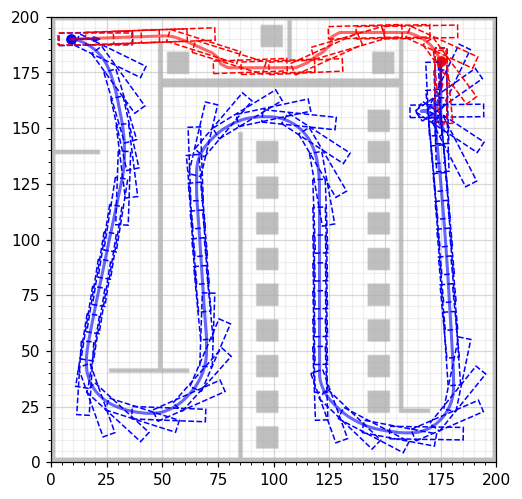

In [10]:
n_ours = [[n_driven["2WS"][:, :3]], [n_driven["4WS"][:, :3]]]
for label, hidden in (("2ws", "shfm4ws"), ("4ws", "shfm2ws")):
    PL.trajectories(narrow_file, n_ours, every_nth=50, run_id="0", silence=True,
                    ignore_planners=BASELINES + "," + hidden,
                    save_file=os.path.join(FIGURE_DIR, "05_%s_only_shortcuts.pdf" % label))
fig = PL.trajectories(narrow_file, n_ours, every_nth=50, run_id="0", silence=True,
                      ignore_planners=BASELINES,
                      save_file=os.path.join(FIGURE_DIR, "05_shortcuts_2ws_4ws.pdf"))

The two paths follow different routes. The 4WS vehicle, in red, takes the top
passage and arrives almost directly, 188.9 cells, with 12 % of its points in
the manoeuvring modes. The 2WS vehicle, in blue, steers its front axle only,
with a minimum turning radius of about twenty grid units, so the passage is
closed to it and the only way to the goal winds through the hall, down and up
twice around its inner walls: 772.9 cells, about four times as long, with
thirteen cusps.

The start of the 2WS path is left as extracted: no connection from the
requested pose meets the conditions of `close_start`, and the path begins 0.44
cells, 5.5 cm, from that pose.

We did not tune the cost function to produce this: the same planner, the same
coefficients and the same transition costs were given two control sets, and
the routes follow from the geometry of the map.

<a id='6'></a>
## 6. The price of the manoeuvring mode

The parameter study of notebook 6 is centred on $k_1 = 10$, $k_2 = 50$. We
solve both problems at those transition costs.

docking         SHFM 2WS  length   98.2   swept area  13.5 m2    2 cusps   manoeuvring   0%
docking         SHFM 4WS  length   89.9   swept area  12.2 m2    2 cusps   manoeuvring   3%
narrow_passage  SHFM 2WS  length  792.8   swept area 144.4 m2   14 cusps   manoeuvring   1%
narrow_passage  SHFM 4WS  length  744.5   swept area 138.8 m2   21 cusps   manoeuvring   8%


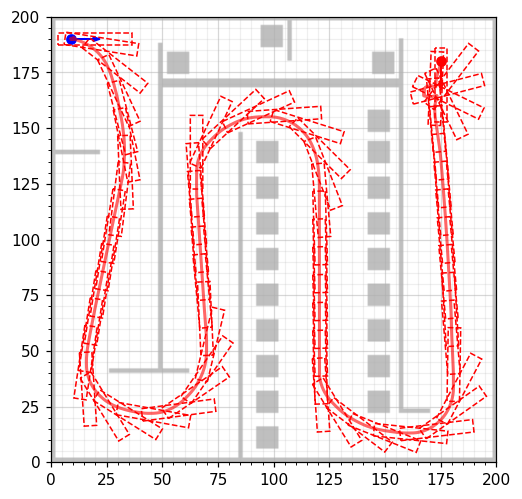

In [11]:
reference = {}
for name, (e, s, g, delta) in (("docking", (env, start, goal, DOCK_DELTA)),
                               ("narrow_passage", (n_env, n_start, n_goal, NP_DELTA))):
    for vehicle in ("2WS", "4WS"):
        p, _ = plan_path(e, s, g, vehicle, delta, k1=10.0, k2=50.0)
        reference[(name, vehicle)] = p
        m = measure(p, e, g)
        print("%-15s SHFM %s  length %6.1f   swept area %5.1f m2   %2d cusps   manoeuvring %3.0f%%"
              % (name, vehicle, m["path_length"], m["swept_area"], m["cusps"],
                 100 * m["manoeuvre"]))

PL.trajectories(docking_file, [[reference[("docking", "2WS")][:, :3]] * n_runs,
                               [reference[("docking", "4WS")][:, :3]] * n_runs],
                every_nth=60, run_id="0", silence=True,
                ignore_planners=BASELINES + ",shfm2ws",
                save_file=os.path.join(FIGURE_DIR, "05_creneau_4ws_k1050.pdf"))
fig = PL.trajectories(narrow_file, [[reference[("narrow_passage", "2WS")][:, :3]],
                                    [reference[("narrow_passage", "4WS")][:, :3]]],
                      every_nth=50, run_id="0", silence=True,
                      ignore_planners=BASELINES + ",shfm2ws",
                      save_file=os.path.join(FIGURE_DIR, "05_4ws_only_shortcuts_k1050.pdf"))

At $(10, 50)$ the 4WS vehicle hardly uses the manoeuvring mode on the docking
problem, 3 % of its points against 26 % at $(2, 3)$, and reaches the bay
almost entirely in navigation, over 89.9 cells. On Narrow-Passage it goes round
the hall like the 2WS vehicle: 752.5 cells against 790.4 for the 2WS one, on
the shipped paths once cleaned (`figures/tables/reference_costs.md`, drawn from
`data/comparison/reference_costs`). Crossing the passage takes a string of
mode switches close to the obstacles, and the solver scales the cost of each
switch by the local cost, which is highest near the walls, while the detour
runs through open space where moving is cheap. With $k_2 = 50$ the detour costs
less; with $k_2 = 3$ the passage does. Section 5 of notebook 6 discusses the
grid of $(k_1, k_2)$ the comparisons' setting was chosen from; its values are
in `figures/tables/parameter_study.md`.

---

Previous: [4. The state system](04_state_system.ipynb)
Next: [6. Discretisation and parameters](06_parameter_study.ipynb)